In [1]:
!pip install -q shap

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import shap

from tensorflow.keras import layers, models, datasets
from keras.preprocessing.image import load_img, img_to_array
from keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.utils.class_weight import compute_class_weight
from sklearn.utils import resample, shuffle

from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Dense, Dropout, Flatten, BatchNormalization

import requests
import zipfile
from typing import Literal

In [3]:
# Criar a pasta para armazenar o dataset
folder = "/content/RAF-DB"
os.makedirs(folder, exist_ok=True)

# URL do dataset no Kaggle
url = "https://www.kaggle.com/api/v1/datasets/download/dollyprajapati182/balanced-raf-db-dataset-7575-grayscale"


# Baixar o arquivo ZIP
response = requests.get(url, stream=True)
response.raise_for_status()

zip_file = f"{folder}/balanced-raf-db-dataset-7575-grayscale.zip"

with open(zip_file, "wb") as file_:
    for block in response.iter_content(chunk_size=1024 * 1024):
        if block:
            file_.write(block)

print("Download concluído!")

Download concluído!


In [4]:
  # Descompactar arquivo ZIP
with zipfile.ZipFile("/content/RAF-DB/balanced-raf-db-dataset-7575-grayscale.zip", "r") as file_:
    file_.extractall("/content/RAF-DB")

print("Dataset extraído com sucesso!")

for root, folders, felis in os.walk("/content/RAF-DB"):
    level = root.replace("/content/RAF-DB", "").count(os.sep)
    print("  " * level + os.path.basename(root) + "/")

Dataset extraído com sucesso!
RAF-DB/
  train/
    happy/
    angry/
    neutral/
    fear/
    surprise/
    sad/
    disgust/
  val/
    happy/
    angry/
    neutral/
    fear/
    surprise/
    sad/
    disgust/
  test/
    happy/
    angry/
    neutral/
    fear/
    surprise/
    sad/
    disgust/


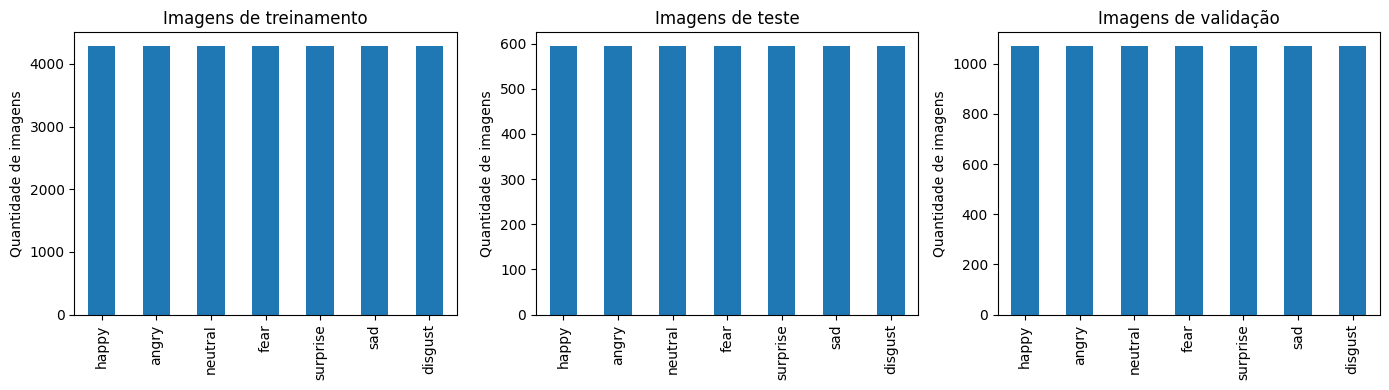

Imagens de treinamento: {'happy': 4289, 'angry': 4289, 'neutral': 4289, 'fear': 4289, 'surprise': 4289, 'sad': 4289, 'disgust': 4289}
Imagens de teste: {'happy': 595, 'angry': 595, 'neutral': 595, 'fear': 595, 'surprise': 595, 'sad': 595, 'disgust': 595}
Imagens de validação: {'happy': 1072, 'angry': 1072, 'neutral': 1072, 'fear': 1072, 'surprise': 1072, 'sad': 1072, 'disgust': 1072}


In [5]:
train_dir = '/content/RAF-DB/train/'
test_dir = '/content/RAF-DB/test/'
val_dir = '/content/RAF-DB/val/'

# Contar imagens de treinamento
train_count = {class_: len(os.listdir(os.path.join(train_dir, class_)))
               for class_ in os.listdir(train_dir)}

# Contar imagens de teste
test_count = {class_: len(os.listdir(os.path.join(test_dir, class_)))
              for class_ in os.listdir(test_dir)}

# Contar imagens de validação
val_count = {class_: len(os.listdir(os.path.join(val_dir, class_)))
              for class_ in os.listdir(val_dir)}

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
pd.Series(train_count).plot(kind="bar", ax=axes[0], title="Imagens de treinamento")
pd.Series(test_count).plot(kind="bar", ax=axes[1], title="Imagens de teste")
pd.Series(val_count).plot(kind="bar", ax=axes[2], title="Imagens de validação")
axes[0].set_ylabel("Quantidade de imagens")
axes[1].set_ylabel("Quantidade de imagens")
axes[2].set_ylabel("Quantidade de imagens")
plt.tight_layout()
plt.show()

print("Imagens de treinamento:", train_count)
print("Imagens de teste:", test_count)
print("Imagens de validação:", val_count)

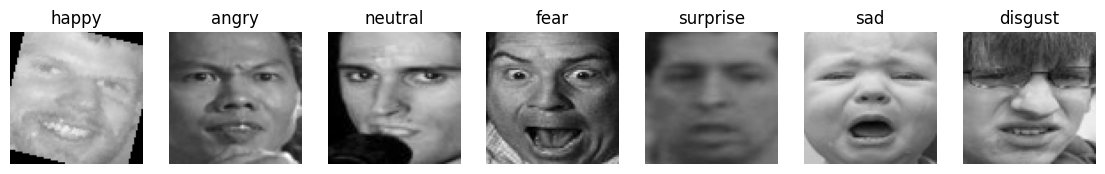

In [6]:
plt.figure(figsize=(14,4))
i = 1
for expression in os.listdir(train_dir):
    img = load_img((train_dir + expression +'/'+ os.listdir(train_dir + expression)[5]))
    plt.subplot(1,7,i)
    plt.imshow(img)
    plt.title(expression)
    plt.axis('off')
    i += 1
plt.show()

In [7]:
# Carregar os conjuntos de treino e teste
def carregar_imagens(path_dir):
    imagens = []
    rotulos = []
    mapping = {
    'angry': 0, 'disgust': 1, 'fear': 2,
    'happy': 3, 'neutral': 4, 'sad': 5, 'surprise': 6
}
    for emocao, rotulo in mapping.items():
        pasta = os.path.join(path_dir, emocao)
        for arquivo in os.listdir(pasta):
            caminho = os.path.join(pasta, arquivo)
            if os.path.isfile(caminho):
                  imagem = load_img(caminho, target_size=(75, 75), color_mode="grayscale")
                  imagens.append(img_to_array(imagem))
                  rotulos.append(rotulo)
    return np.array(imagens, dtype=np.float32) / 255.0, np.array(rotulos, dtype=np.int32)

X_train, y_train = carregar_imagens(train_dir)
X_test, y_test = carregar_imagens(test_dir)
X_val, y_val = carregar_imagens(val_dir)


print("Imagens para treinamento:", len(X_train))
print("Imagens para teste:", len(X_test))
print("Imagens para validação:", len(X_val))

Imagens para treinamento: 30023
Imagens para teste: 4165
Imagens para validação: 7504


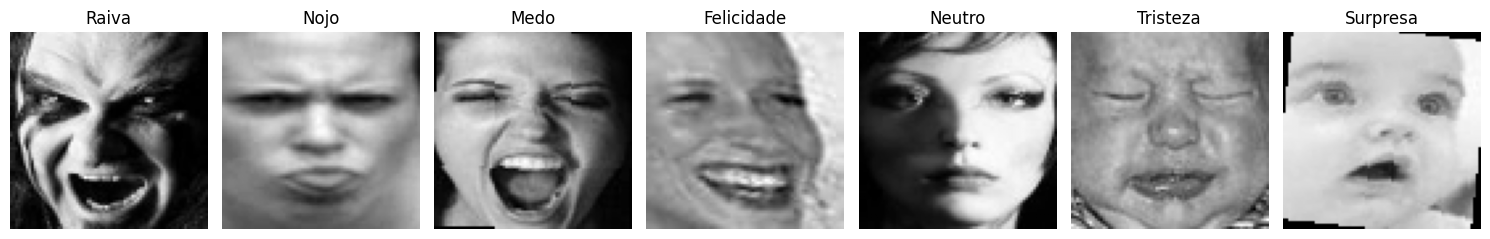

In [8]:
classes = ['Raiva', 'Nojo', 'Medo', 'Felicidade', 'Neutro', 'Tristeza', 'Surpresa']

first_image_index = {}
for i, label in enumerate(y_train):
    first_image_index.setdefault(label, i)

fig, axes = plt.subplots(1, 7, figsize=(15, 4))

for i, ax in enumerate(axes):
    ax.imshow(X_train[first_image_index[i]].reshape(75, 75), cmap='gray')
    ax.set_title(classes[i])
    ax.axis('off')

plt.tight_layout()
plt.show()

In [9]:
# Definir dimensões da imagem
image_height = 75
image_width = 75

# Criar o modelo
model = Sequential()

model.add(BatchNormalization(input_shape=(image_height, image_width, 1)))
model.add(Conv2D(512, (3,3), padding='same', activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2)))
model.add(Dropout(0.2)) # Adiciona a camada de dropout

model.add(Conv2D(256, (3,3), padding='same', activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2)))
model.add(Dropout(0.2)) # Adiciona a camada de dropout

model.add(Conv2D(128, (3, 3), padding='same', activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2)))
model.add(Dropout(0.2)) # Adiciona a camada de dropout

model.add(Conv2D(64, (3,3), padding='same', activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2)))
model.add(Dropout(0.2)) # Adiciona a camada de dropout

model.add(Flatten())
model.add(Dense(32, activation='relu'))
model.add(Dropout(0.2)) # Adiciona a camada de dropout
model.add(Dense(7, activation='softmax')) # Especifica 'softmax' como a função de ativação

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/normalization/batch_normalization.py:142: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ batch_normalization             │ (None, 75, 75, 1)      │             4 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 75, 75, 512)    │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 37, 37, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 37, 37, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 37, 37, 256)    │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 18, 18, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 18, 18, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 18, 18, 128)    │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 9, 9, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 9, 9, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 9, 9, 64)       │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        32,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,586,891 (6.05 MB)

 Trainable params: 1,586,889 (6.05 MB)

 Non-trainable params: 2 (8.00 B)

In [10]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "best_cnn_emotion.weights.h5",
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-5,
        verbose=1
    )
]

history = model.fit(
    X_train,
    y_train,
    epochs=200,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=callbacks,
    verbose=1
)

Epoch 1/200
470/470 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step - accuracy: 0.2277 - loss: 1.8533
Epoch 1: val_loss improved from None to 1.39952, saving model to best_cnn_emotion.weights.h5

Epoch 1: finished saving model to best_cnn_emotion.weights.h5
470/470 ━━━━━━━━━━━━━━━━━━━━ 113s 192ms/step - accuracy: 0.3026 - loss: 1.7329 - val_accuracy: 0.4832 - val_loss: 1.3995 - learning_rate: 0.0010
Epoch 2/200
469/470 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step - accuracy: 0.4794 - loss: 1.3716
Epoch 2: val_loss improved from 1.39952 to 1.09614, saving model to best_cnn_emotion.weights.h5

Epoch 2: finished saving model to best_cnn_emotion.weights.h5
470/470 ━━━━━━━━━━━━━━━━━━━━ 81s 172ms/step - accuracy: 0.5007 - loss: 1.3202 - val_accuracy: 0.6101 - val_loss: 1.0961 - learning_rate: 0.0010
Epoch 3/200
469/470 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step - accuracy: 0.5586 - loss: 1.1704
Epoch 3: val_loss improved from 1.09614 to 0.93039, saving model to best_cnn_emotion.weights.h5

Epoch 3: finished saving model t

In [11]:
model.save("emotion_detectetion.keras")
print("Modelo salvo com sucesso.")

Modelo salvo com sucesso.


131/131 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - accuracy: 0.9160 - loss: 0.2831
Acurácia no teste: 0.9160
Perda no teste: 0.2831
66/66 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step
              precision    recall  f1-score   support

       Raiva       0.94      0.96      0.95       595
        Nojo       0.91      0.93      0.92       595
        Medo       0.97      0.98      0.98       595
  Felicidade       0.93      0.90      0.91       595
      Neutro       0.83      0.85      0.84       595
    Tristeza       0.89      0.85      0.87       595
    Surpresa       0.94      0.95      0.94       595

    accuracy                           0.92      4165
   macro avg       0.92      0.92      0.92      4165
weighted avg       0.92      0.92      0.92      4165



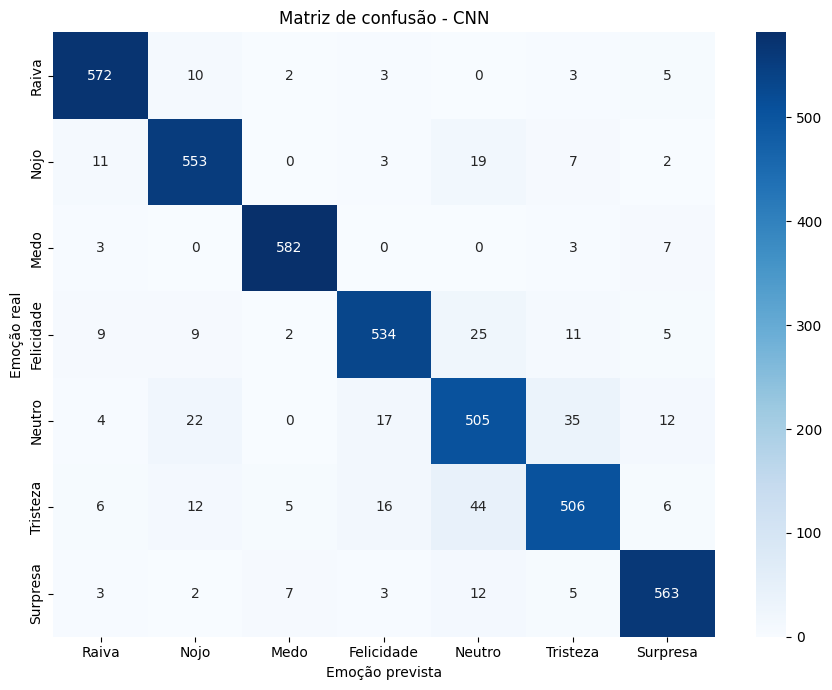

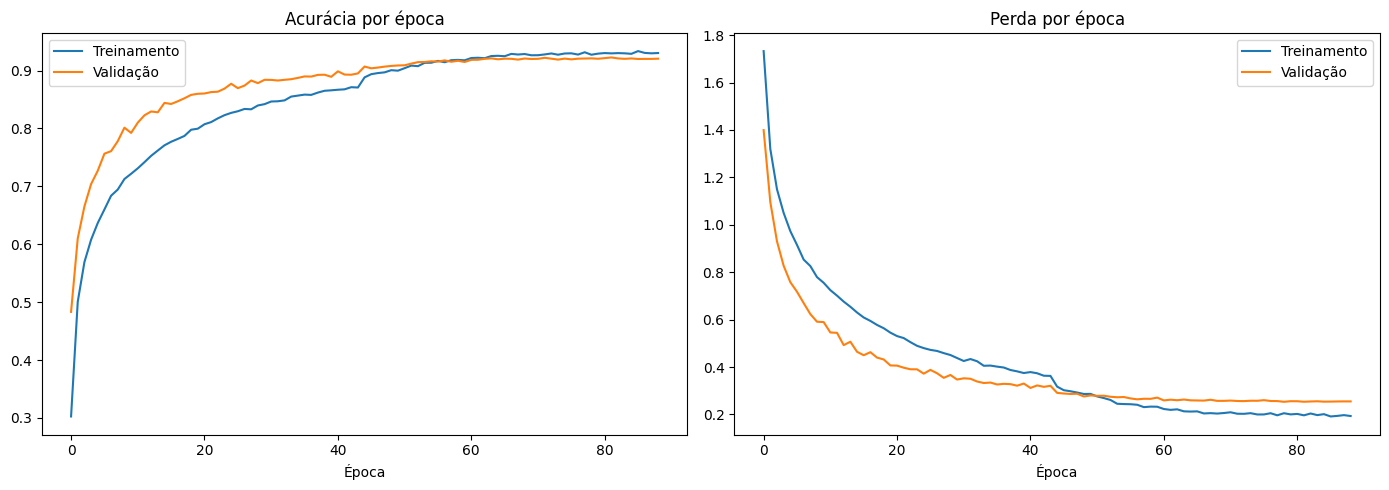

In [12]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)
print(f"Acurácia no teste: {test_accuracy:.4f}")
print(f"Perda no teste: {test_loss:.4f}")

y_pred = np.argmax(model.predict(X_test, batch_size=64), axis=1)
nomes_classes = ["Raiva", "Nojo", "Medo", "Felicidade", "Neutro", "Tristeza", "Surpresa"]
print(classification_report(y_test, y_pred, labels=list(range(7)), target_names=nomes_classes, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=list(range(7)))
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=nomes_classes, yticklabels=nomes_classes)
plt.xlabel("Emoção prevista")
plt.ylabel("Emoção real")
plt.title("Matriz de confusão - CNN")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history.history["accuracy"], label="Treinamento")
axes[0].plot(history.history["val_accuracy"], label="Validação")
axes[0].set_title("Acurácia por época")
axes[0].set_xlabel("Época")
axes[0].legend()
axes[1].plot(history.history["loss"], label="Treinamento")
axes[1].plot(history.history["val_loss"], label="Validação")
axes[1].set_title("Perda por época")
axes[1].set_xlabel("Época")
axes[1].legend()
plt.tight_layout()
plt.show()

In [13]:
resultados = model.evaluate(X_test, y_test, verbose=0)
for nome, valor in zip(model.metrics_names, resultados):
    print(f"{nome}: {valor:.4f}")

loss: 0.2831
compile_metrics: 0.9160


In [ ]:
# Selecionar imagens de referência do treinamento
np.random.seed(42)

indices = np.random.choice(
    len(X_train),
    size=min(30, len(X_train)),
    replace=False
)

background = X_train[indices]

# Selecionar poucas imagens para explicar
X_explain = X_test[:5]

# Criar o explicador SHAP
explainer = shap.GradientExplainer(model, background)

# Calcular os valores SHAP
shap_values = explainer.shap_values(X_explain)

print("Formato das imagens:", X_explain.shape)
print("Explicações SHAP calculadas.")

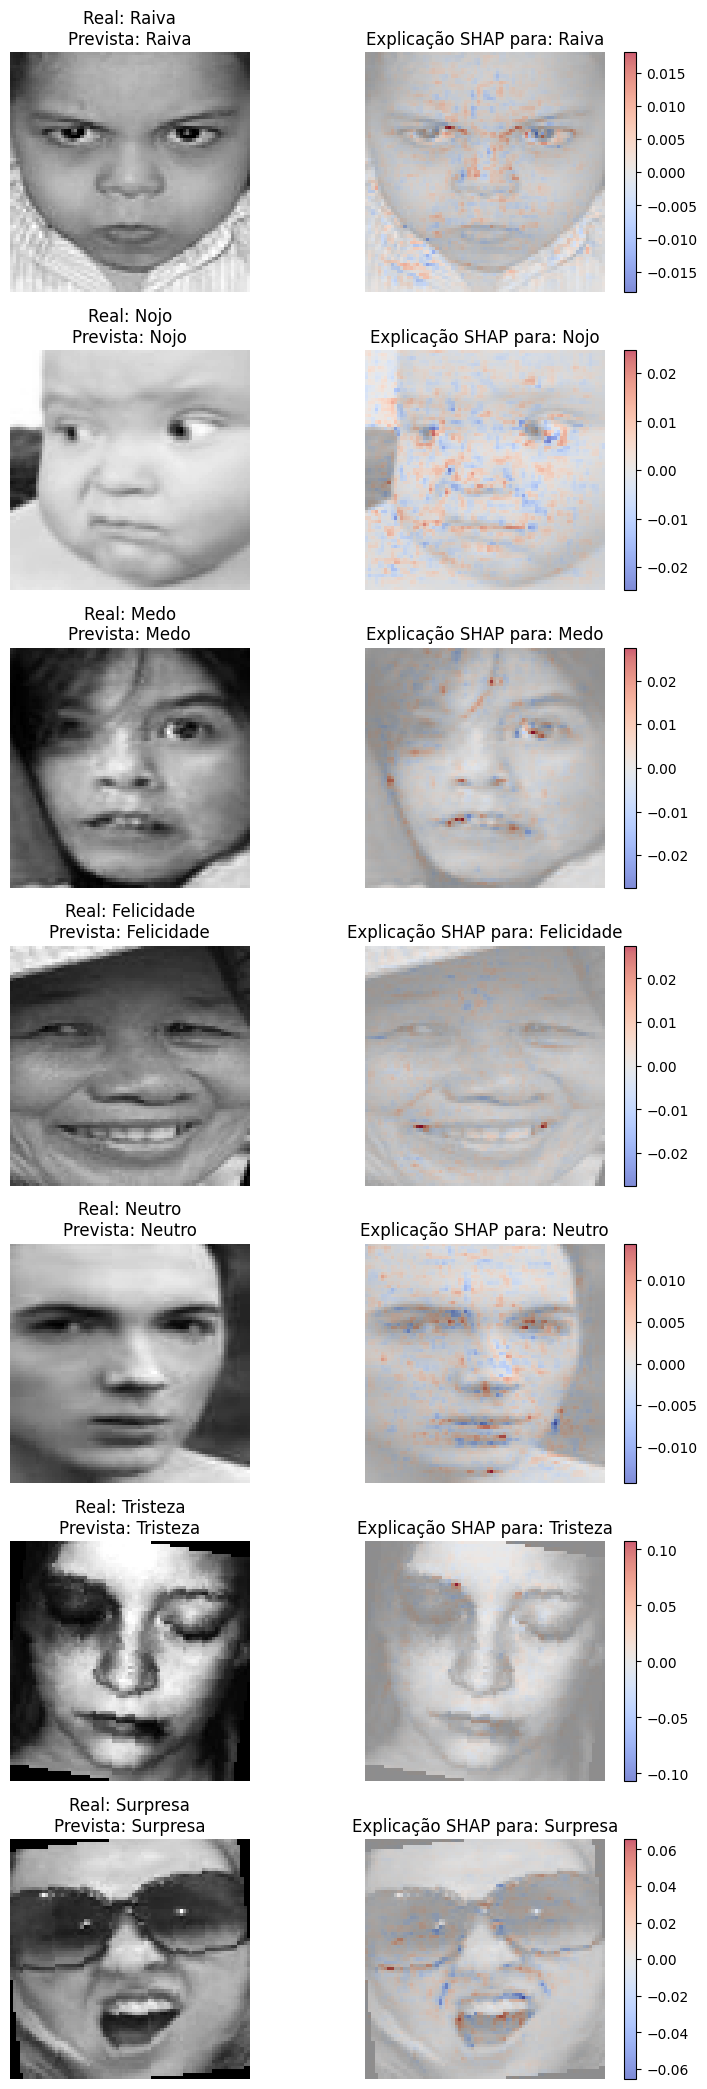

In [17]:
indices_por_classe = {}
for idx, label in enumerate(y_test):
    if label not in indices_por_classe and len(indices_por_classe) < 7:
        indices_por_classe[label] = idx

indices_selecionados = [indices_por_classe[i] for i in range(7)]

X_explain_7 = X_test[indices_selecionados]
y_explain_7 = y_test[indices_selecionados]

shap_values_7 = explainer.shap_values(X_explain_7)

if isinstance(shap_values_7, list):
    valores_por_classe_7 = shap_values_7
else:
    shap_values_7 = np.asarray(shap_values_7)
    if shap_values_7.ndim == 5:
        valores_por_classe_7 = [
            shap_values_7[..., i]
            for i in range(shap_values_7.shape[-1])
        ]
    else:
        raise ValueError("Formato SHAP inesperado: " + str(shap_values_7.shape))

predicoes_7 = np.argmax(model.predict(X_explain_7, verbose=0), axis=1)

fig, axes = plt.subplots(7, 2, figsize=(8, 3 * 7))

for i in range(7):
    classe_real = y_explain_7[i]
    classe_prevista = predicoes_7[i]

    imagem = X_explain_7[i].squeeze()
    explicacao = valores_por_classe_7[classe_real][i].sum(axis=-1)

    limite = np.max(np.abs(explicacao)) + 1e-8

    axes[i, 0].imshow(imagem, cmap="gray")
    axes[i, 0].set_title(f"Real: {nomes_classes[classe_real]}\nPrevista: {nomes_classes[classe_prevista]}")

    axes[i, 1].imshow(imagem, cmap="gray")
    mapa = axes[i, 1].imshow(
        explicacao,
        cmap="coolwarm",
        alpha=0.65,
        vmin=-limite,
        vmax=limite
    )
    axes[i, 1].set_title(f"Explicação SHAP para: {nomes_classes[classe_real]}")
    fig.colorbar(mapa, ax=axes[i, 1], fraction=0.046)

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()